# Project overview

This project analyses the **Mice Protein Expression** dataset (Higuera, Gardiner & Cios, 2015, *PLoS ONE*). Expression levels of **77 proteins** were measured in the cortex of **72 mice**, with **15 technical replicates per mouse** (1,080 rows in total).

What are the 15 measurements per mouse?
- They are **technical replicates**, not repeated measurements over time.
- Each mouse's brain tissue was collected **once**.
- The sample was measured with RPPA as **3 replicates × 5 dilutions = 15 measurements**.
- So the 15 rows of one mouse are very similar and **not independent**.
- Consequence: train/test splits must be done **by mouse**, not by row.

The mice belong to **8 classes**, defined by three factors.

Each class name has 3 parts, for example `t-CS-m`:
- **c / t**: normal mouse / Down syndrome mouse
- **CS / SC**: learning test / no-learning control
- **m / s**: memantine (drug) / saline (no drug)

Key biological groups:
- `c-CS-s`: normal learning
- `t-CS-s`: failed learning (Down syndrome mice without the drug)
- `t-CS-m`: rescued learning (Down syndrome mice given memantine)

## Setup
- All libraries and shared settings (colours, class order) are loaded once here.

In [521]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

# Data and charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap
import xlrd

# Statistics
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.stats import mannwhitneyu, kruskal, false_discovery_control, spearmanr

# Machine learning
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, cross_val_score,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.impute import KNNImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.inspection import permutation_importance

# Colours used in all charts
SOFT_BLUE, SOFT_RED = "#86b0e3", "#ec9a99"
GREY, PURPLE = "#c8c8c4", "#b9a4e0"
def clean_axes(ax):
    """Same calm style for every chart."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#999999")
    ax.tick_params(colors="#444444")

## Step 1: Setup and first look at the data


In [522]:
df = pd.read_excel("data/Data_Cortex_Nuclear.xls")
# MouseID looks like "309_1" -> mouse 309, replicate 1
df[["Mouse", "Replicate"]] = df["MouseID"].str.split("_", expand=True)
df["Replicate"] = df["Replicate"].astype(int)
df.head(15)

,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,...,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class,Mouse,Replicate
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,...,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m,309,1
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,...,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m,309,2
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,...,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m,309,3
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,...,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m,309,4
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,...,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m,309,5
5,309_6,0.447506,0.628176,0.367388,2.385939,4.807635,0.218578,0.176233,2.141282,0.195188,...,0.116657,0.140766,0.142180,1.816389,Control,Memantine,C/S,c-CS-m,309,6
6,309_7,0.428033,0.573696,0.342709,2.334224,4.473130,0.225173,0.184004,2.012414,0.195789,...,0.137229,0.156682,0.157499,1.528484,Control,Memantine,C/S,c-CS-m,309,7
7,309_8,0.416923,0.564036,0.327703,2.260135,4.268735,0.214834,0.179668,2.007985,0.189803,...,0.123376,0.155612,0.159409,1.652658,Control,Memantine,C/S,c-CS-m,309,8
8,309_9,0.386311,0.538428,0.317720,2.125725,4.063950,0.207222,0.167778,1.861514,0.180684,...,0.125173,0.152711,0.158235,1.834599,Control,Memantine,C/S,c-CS-m,309,9
9,309_10,0.380827,0.499294,0.362462,2.096266,3.598587,0.227649,0.188093,1.717861,0.188093,...,0.146133,0.188849,0.192334,1.516862,Control,Memantine,C/S,c-CS-m,309,10


##  Data investigation

### a) How many mice are there?


In [523]:
print("Unique mice:", df["Mouse"].nunique())

Unique mice: 72


In [524]:
print("\nGenotype:", df["Genotype"].unique())


Genotype: ['Control' 'Ts65Dn']


In [525]:
print("Behavior:", df["Behavior"].unique())

Behavior: ['C/S' 'S/C']


In [526]:
print("Treatment:", df["Treatment"].unique())

Treatment: ['Memantine' 'Saline']


In [527]:
print("Classes:", df["class"].unique())

Classes: ['c-CS-m' 'c-SC-m' 'c-CS-s' 'c-SC-s' 't-CS-m' 't-SC-m' 't-CS-s' 't-SC-s']


In [528]:
print("Mice per genotype:\n", df.groupby("Genotype")["Mouse"].nunique())

Mice per genotype:
 Genotype
Control    38
Ts65Dn     34
Name: Mouse, dtype: int64


In [529]:
print("\nMice per group:\n", df.groupby(["Genotype", "Behavior", "Treatment"])["Mouse"].nunique())


Mice per group:
 Genotype  Behavior  Treatment
Control   C/S       Memantine    10
                    Saline        9
          S/C       Memantine    10
                    Saline        9
Ts65Dn    C/S       Memantine     9
                    Saline        7
          S/C       Memantine     9
                    Saline        9
Name: Mouse, dtype: int64


In [530]:
class_order = sorted(df["class"].unique())
genotype_colors = {"Control": SOFT_BLUE, "Ts65Dn": SOFT_RED}

# Check: the order contains exactly the classes found in the data
assert set(class_order) == set(df["class"].unique())
classes_per_mouse = df.groupby("Mouse")["class"].nunique()
print("\nEach mouse has one class:", (classes_per_mouse == 1).all())


Each mouse has one class: True


### Separating protein columns from meta columns
- Protein columns end in `_N`. The `_N` means the protein was measured in the **nuclear** fraction of the cortex.

In [531]:
protein_cols = [c for c in df.columns if c.endswith("_N")]
meta_cols = [c for c in df.columns if c not in protein_cols]
print("Number of protein columns:", len(protein_cols))
print("Meta columns:", meta_cols)
assert len(protein_cols) in (77, 76), f"Unexpected number of proteins: {len(protein_cols)}"

Number of protein columns: 77
Meta columns: ['MouseID', 'Genotype', 'Treatment', 'Behavior', 'class', 'Mouse', 'Replicate']


In [532]:
print("Shape:", df.shape)
print("Proteins:", len(protein_cols))
print("Unique mice:", df["Mouse"].nunique())

Shape: (1080, 84)
Proteins: 77
Unique mice: 72


In [533]:
print("\nMeasurements per mouse:\n", df.groupby("Mouse").size().value_counts())


Measurements per mouse:
 15    72
Name: count, dtype: int64


In [534]:
print("\nMice per class:\n", df.groupby("class")["Mouse"].nunique())


Mice per class:
 class
c-CS-m    10
c-CS-s     9
c-SC-m    10
c-SC-s     9
t-CS-m     9
t-CS-s     7
t-SC-m     9
t-SC-s     9
Name: Mouse, dtype: int64


In [535]:
print("\nRows per class:\n", df["class"].value_counts().sort_index())


Rows per class:
 class
c-CS-m    150
c-CS-s    135
c-SC-m    150
c-SC-s    135
t-CS-m    135
t-CS-s    105
t-SC-m    135
t-SC-s    135
Name: count, dtype: int64


In [536]:
missing = df[protein_cols].isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("\nTop missing proteins (%):\n", (missing / len(df) * 100).round(1).head(5))


Top missing proteins (%):
 BCL2_N       26.4
H3MeK4_N     25.0
BAD_N        19.7
EGR1_N       19.4
H3AcK18_N    16.7
dtype: float64


In [537]:
print("\nRows with any missing protein:", df[protein_cols].isna().any(axis=1).sum())


Rows with any missing protein: 528


In [538]:
df.to_pickle("mice_raw.pkl")

### b) Protein summary statistics
- Proteins are on very different scales, so they must be **standardised** before modelling.

In [539]:
summary = df[protein_cols].describe().T[["mean", "std", "min", "max"]]
summary.sort_values("mean")

,mean,std,min,max
GFAP_N,0.120889,0.013233,0.086114,0.213621
ARC_N,0.121521,0.014276,0.067254,0.158748
pS6_N,0.121521,0.014276,0.067254,0.158748
GluR4_N,0.126560,0.026885,0.072580,0.537004
pCFOS_N,0.131053,0.023863,0.085419,0.256529
...,...,...,...,...
PSD95_N,2.235236,0.254395,1.206098,2.877873
NR1_N,2.297269,0.347293,1.330831,3.757641
ERK_N,2.474492,0.653397,1.131796,5.198404
pCAMKII_N,3.537109,1.295169,1.343998,7.464070


### Correlation between proteins
- Correlation shows which proteins rise and fall together.
- The 15 replicates of a mouse are near-copies, so we first **average them per mouse**.
  This gives 72 independent points instead of 1,080 dependent ones.
- A heatmap shows the overall pattern, and a ranked list shows the strongest pairs.

In [540]:
# One row per mouse: average of its 15 replicates
mouse_means = df.groupby("Mouse")[protein_cols].mean()
corr = mouse_means.corr()

# Each pair only once (upper triangle)
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack().reset_index()
pairs.columns = ["Protein 1", "Protein 2", "r"]

high_corr = (pairs[pairs["r"].abs() > 0.9]
             .sort_values("r", key=abs, ascending=False)
             .round(2)
             .reset_index(drop=True))
high_corr

,Protein 1,Protein 2,r
0,ARC_N,pS6_N,1.00
1,DYRK1A_N,BRAF_N,0.98
2,DYRK1A_N,ITSN1_N,0.98
3,DYRK1A_N,pERK_N,0.98
4,pERK_N,BRAF_N,0.97
5,ITSN1_N,BRAF_N,0.96
6,pAKT_N,pMEK_N,0.95
7,ITSN1_N,pERK_N,0.95
8,pBRAF_N,pMEK_N,0.94
9,pAKT_N,pBRAF_N,0.93


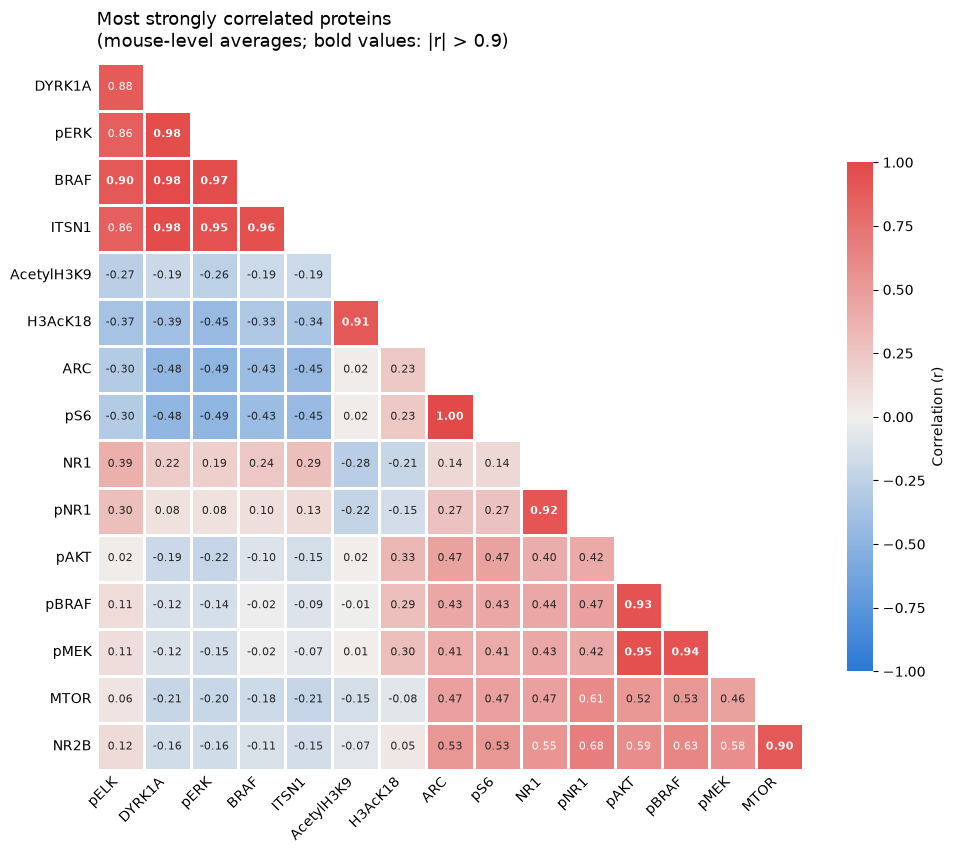

In [541]:
# 1. Keep only proteins that appear in a strong pair
top = sorted(set(high_corr["Protein 1"]) | set(high_corr["Protein 2"]))
sub = corr.loc[top, top]

# 2. Put similar proteins next to each other (clustering)
order = sub.index[leaves_list(linkage(sub, method="average"))]
sub = sub.loc[order, order]

# 3. Shorter labels: remove "_N"
sub.index = sub.columns = [p.removesuffix("_N") for p in sub.index]

# 4. Show only the lower half (drop the empty first row and last column)
sub = sub.iloc[1:, :-1]
hide_upper = np.triu(np.ones(sub.shape, dtype=bool), k=1)

# 5. Blue (negative) - grey (zero) - red (positive)
cmap = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(sub, mask=hide_upper, cmap=cmap, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=2, linecolor="white", square=True,
            cbar_kws={"label": "Correlation (r)", "shrink": 0.7}, ax=ax)

# 6. Bold the strong correlations
for text in ax.texts:
    if abs(float(text.get_text())) >= 0.9:
        text.set_fontweight("bold")

ax.set_title("Most strongly correlated proteins\n(mouse-level averages; bold values: |r| > 0.9)",
             fontsize=13, loc="left", pad=12)
ax.tick_params(length=0)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### What do these correlations mean?

The 14 strongly correlated pairs can be explained by **4 reasons**.

#### 1. Proteins in the same signalling pathway (a "chain reaction")
Many of these proteins belong to the **MAPK pathway**, a chain in which each protein switches on the next:

**BRAF → MEK → ERK → ELK**

- When one step is active, the next steps tend to be active too, so their levels rise and fall together.
- Pairs explained by this: **pBRAF–pMEK**, **pERK–BRAF**, **pELK–BRAF**.
- **pAKT** belongs to a neighbouring pathway (PI3K–AKT). It is switched on by the same growth signals,
  which explains **pAKT–pMEK** and **pAKT–pBRAF**.
- These pathways are central to **learning and memory**: they turn a signal at the synapse into changes in the brain cell.

#### 2. A protein and its "active" form
The letter **p** in front of a name means *phosphorylated*: the protein has been switched on.

- **NR1 / pNR1**: NR1 is part of the **NMDA receptor**, the main "learning receptor" in the brain.
  The more NR1 a cell has, the more of it can be switched on, so the two go together.
- This matters for the project: **memantine works by blocking NMDA receptors.**

#### 3. Same type of chemical mark
- **AcetylH3K9 / H3AcK18** are both **acetylation marks on histone H3**, the protein that DNA is wrapped around.
- Both marks "open up" DNA so that genes can be read, and they are often added together.
- They are linked to forming long-term memories.

#### 4. Down syndrome genes
- **DYRK1A** and **ITSN1** are both encoded on **chromosome 21**, the chromosome present in three copies in
  Down syndrome. In the trisomic mice, both are present in an extra copy.
- They correlate very strongly with **BRAF** and **pERK** (r = 0.95–0.98), forming the tightest group in the data.
- This group could reflect a shared biological role, or a shared technical effect from the measurements. Correlation alone cannot tell us which.

#### Less obvious pairs
- **MTOR / NR2B** (r = 0.90): mTOR controls protein production at synapses, and NR2B is another NMDA receptor part.
  Both are involved in synaptic plasticity (how connections between brain cells change with learning),
  but the strong link needs further study.

#### Data error
- **ARC / pS6** (r = 1.00): ARC is a "memory gene" switched on during learning, while pS6 is a ribosome protein.
  They are **different proteins**, so identical values are impossible in real measurements.
  This is a **duplicated column** in the dataset, and pS6_N will be removed.

#### Why this matters for the analysis
- Correlation **does not mean** one protein causes the other. It only shows they change together.
- Strongly correlated proteins carry **similar information**. When a model picks one of them as "important",
  the others in the same group may be just as important.

# Step 2: Handling missing values

Plan:
- Remove the duplicate column (pS6_N)
- Find out *where* values are missing: random rows, or whole mice?
- Remove rows that are almost empty
- Fill small gaps using the **same mouse's** other replicates
- Leave the remaining gaps to be filled safely during modelling (Step 5)

## Find and remove identical columns
Method:
1. **Screen:** find protein pairs with correlation of (almost) exactly 1
2. **Confirm:** check that their values are really identical with `.equals()`
   (r = 1 alone is not proof: a column that is always double another also has r = 1)
3. **Remove:** drop the second column of each confirmed identical pair

In [542]:
# Step 1: screen. Find pairs with correlation ~ 1 (all rows)
corr_rows = df[protein_cols].corr()
mask = np.triu(np.ones(corr_rows.shape, dtype=bool), k=1)
pairs_rows = corr_rows.where(mask).stack().reset_index()
pairs_rows.columns = ["Protein 1", "Protein 2", "r"]
candidates = pairs_rows[pairs_rows["r"] > 0.999].copy()

# Step 2: confirm. Are the values really identical?
candidates["identical"] = [df[p1].equals(df[p2])
                           for p1, p2 in zip(candidates["Protein 1"], candidates["Protein 2"])]
candidates

,Protein 1,Protein 2,r,identical
2666,ARC_N,pS6_N,1.0,True


In [543]:
# Step 2: remove. Drop the second column of each identical pair
to_drop = candidates.loc[candidates["identical"], "Protein 2"].unique().tolist()
print("Dropping:", to_drop)

df = df.drop(columns=to_drop)
protein_cols = [c for c in df.columns if c.endswith("_N")]
print("Proteins now:", len(protein_cols))

Dropping: ['pS6_N']
Proteins now: 76


## Where are the values missing?
- For each mouse and protein, we calculate the share of its 15 replicates that are missing.
- **Fully missing** = the protein was never measured for that mouse.
- **Partly missing** = only some replicates are missing.

In [544]:
# Share of missing replicates for each mouse x protein
missing_by_mouse = df[protein_cols].isna().groupby(df["Mouse"]).mean()
cols_with_missing = missing_by_mouse.columns[missing_by_mouse.sum() > 0]
m = missing_by_mouse[cols_with_missing]
display(m)

,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,pNUMB_N,RAPTOR_N,TIAM1_N,pP70S6_N,BAD_N,BCL2_N,pCFOS_N,H3AcK18_N,EGR1_N,H3MeK4_N
Mouse,,,,,,,,,,,,,,,,,,,,,
18899,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
293,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
294,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
309,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
311,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50810E,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50810F,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
J1291,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [545]:
summary = pd.DataFrame({
    "mice_fully_missing": (m == 1).sum(),
    "mice_partly_missing": ((m > 0) & (m < 1)).sum(),
}).sort_values("mice_fully_missing", ascending=False)

summary.head(10)

,mice_fully_missing,mice_partly_missing
BCL2_N,19,0
H3MeK4_N,18,0
EGR1_N,14,0
BAD_N,14,1
H3AcK18_N,12,0
pCFOS_N,5,0
ELK_N,1,1
Bcatenin_N,1,1
pCREB_N,0,1
ITSN1_N,0,1


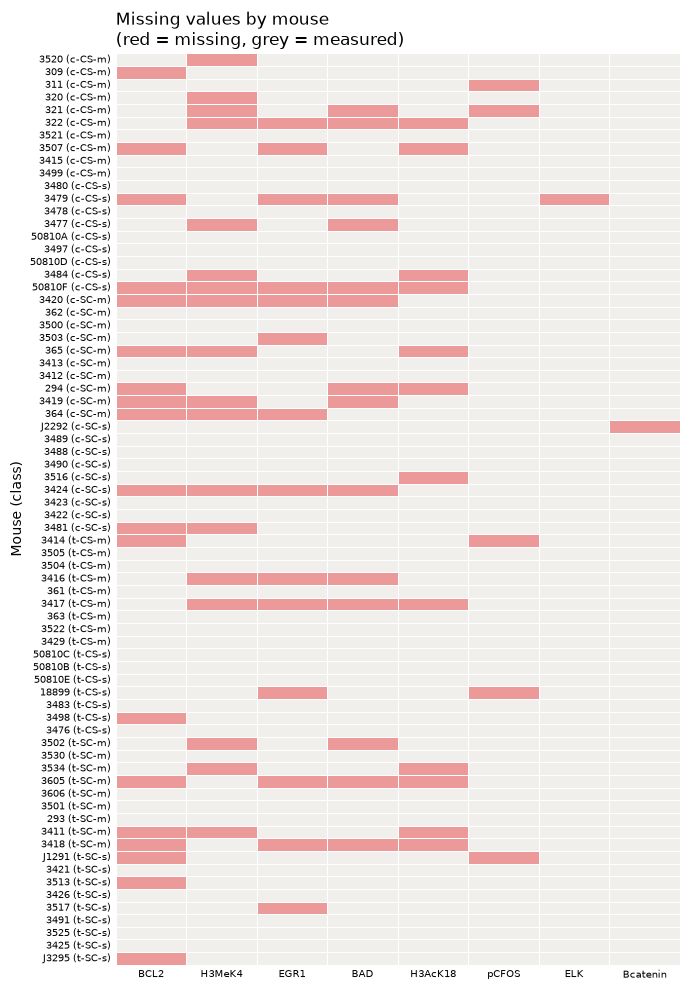

In [546]:
show = summary.index[summary["mice_fully_missing"] > 0]
plot_data = missing_by_mouse[show].copy()
plot_data.columns = [c.removesuffix("_N") for c in plot_data.columns]

# Sort mice by class so the groups are easy to compare
mouse_class = df.groupby("Mouse")["class"].first()
plot_data = plot_data.loc[mouse_class.sort_values().index]

fig, ax = plt.subplots(figsize=(7, 10))
sns.heatmap(plot_data, cmap=["#f0efec", SOFT_RED], cbar=False,
            linewidths=0.5, linecolor="white",
            yticklabels=[f"{m} ({mouse_class[m]})" for m in plot_data.index], ax=ax)
ax.set_title("Missing values by mouse\n(red = missing, grey = measured)", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Mouse (class)")
ax.tick_params(length=0, labelsize=7)
plt.tight_layout()
plt.show()

### How to read the chart
- Each **row** is a mouse (class in brackets), and each **column** is a protein.
- **Red** = the protein was never measured for that mouse, **grey** = measured.

### What the chart shows
**1. Looking down the columns (proteins)**
- Missing values are concentrated in **5 proteins**: BCL2, H3MeK4, EGR1, BAD and H3AcK18.
- **BCL2** has the most red (19 mice), followed by **H3MeK4** (18 mice).
- **pCFOS, ELK and Bcatenin** are almost complete (5, 1 and 1 mice missing).
- The other **68 proteins** are complete for every mouse, so they are not shown.

**2. Looking across the rows (mice)**
- **37 of 72 mice** are complete (all-grey rows).
- **35 mice** are missing at least one protein.
- Red often appears **in blocks**: some mice miss 4–5 proteins together (e.g. 50810F, 3420, 3424).
  This suggests these proteins were measured together (e.g. on the same slide or batch),
  and the measurement failed for those mice.

**3. Comparing the classes**
- Red appears in **all 8 classes**, so the missing values are **not linked to one group**.
- This matters: if one class were missing much more often, filling the gaps could bias the results.
- The failed-learning group (**t-CS-s**) is the most complete: only 2 of its 7 mice have gaps.

### Conclusion
- Missing values occur in **whole mice**, not random rows, so they cannot be filled from the mouse's own replicates.
- They are spread across all classes, so filling them **during modelling** (Step 5, with KNNImputer)
  is a reasonable choice.

### How many replicates are missing per mouse and protein?
- For each mouse × protein: number of missing replicates out of the mouse's rows (normally 15).
- **Fully missing** = all replicates missing, **partly missing** = only some.

In [547]:
missing_count = df[protein_cols].isna().groupby(df["Mouse"]).sum()   # missing replicates
rows_per_mouse = df.groupby("Mouse").size()                           # usually 15

gaps = missing_count.stack().rename("missing").reset_index()
gaps.columns = ["Mouse", "protein", "missing"]
gaps = gaps[gaps["missing"] > 0]
gaps["of_rows"] = gaps["Mouse"].map(rows_per_mouse)
gaps["type"] = np.where(gaps["missing"] == gaps["of_rows"], "fully missing", "partly missing")

print(gaps["type"].value_counts())
gaps[gaps["type"] == "partly missing"]

type
fully missing     84
partly missing    45
Name: count, dtype: int64


,Mouse,protein,missing,of_rows,type
1748,3426,DYRK1A_N,3,15,partly missing
1749,3426,ITSN1_N,3,15,partly missing
1750,3426,BDNF_N,3,15,partly missing
1751,3426,NR1_N,3,15,partly missing
1752,3426,NR2A_N,3,15,partly missing
1753,3426,pAKT_N,3,15,partly missing
1754,3426,pBRAF_N,3,15,partly missing
1755,3426,pCAMKII_N,3,15,partly missing
1756,3426,pCREB_N,3,15,partly missing
1757,3426,pELK_N,3,15,partly missing


- **84** mouse × protein gaps are **fully missing** (e.g. mouse 294: no BAD, BCL2 or H3AcK18 at all).
- **45** are **partly missing**, but **43 of them come from mouse 3426**: its last 3 replicates are missing
  43 proteins at once. These 3 almost-empty rows are removed next.
- Only **2** real partly-missing gaps remain (3479: MEK, 4 of 15; 365: BAD, 3 of 15).
  They are filled with the mouse's own average.

## Remove almost-empty rows
- Some rows are missing many proteins at once and carry almost no information.

In [548]:
row_missing = df[protein_cols].isna().sum(axis=1)
print(df.loc[row_missing > 10, ["MouseID", "class"]].assign(n_missing=row_missing[row_missing > 10]))

df = df[row_missing <= 10].copy()
print("Rows left:", len(df))

     MouseID   class  n_missing
987  3426_13  t-SC-s         43
988  3426_14  t-SC-s         43
989  3426_15  t-SC-s         43
Rows left: 1077


## Fill small gaps with the same mouse's average
- If a mouse has *some* replicates of a protein, we fill the gaps with **that mouse's own average**.
- This is safe: it uses only the mouse's own measurements and **never uses the class label**.

In [549]:
before = df[protein_cols].isna().sum().sum()

df[protein_cols] = (df.groupby("Mouse")[protein_cols]
                      .transform(lambda s: s.fillna(s.mean())))

after = df[protein_cols].isna().sum().sum()
print("Missing values before:", before, "| after:", after)

still_missing = df[protein_cols].isna().sum()
still_missing = still_missing[still_missing > 0].sort_values(ascending=False)
print("\nMice still missing each protein:\n", (still_missing / 15).round().astype(int))

Missing values before: 1267 | after: 1260

Mice still missing each protein:
 BCL2_N        19
H3MeK4_N      18
EGR1_N        14
BAD_N         14
H3AcK18_N     12
pCFOS_N        5
ELK_N          1
Bcatenin_N     1
dtype: int64


## What about the remaining gaps?
The remaining gaps are proteins that were **never measured** for some mice.

Why we do **not** fill them with the class average (a common mistake):
- The class average uses the **answer** (the class label) to fill the data.
- The model would then learn from that filled-in value, which makes accuracy look better than it really is.
  This is called **data leakage**.

Instead, the remaining gaps are filled **inside the model pipeline** in Step 5 (`KNNImputer`), learning only from the training mice.

In [550]:
df.to_pickle("mice_step2.pkl")
print("Saved:", df.shape, "| mice:", df["Mouse"].nunique())

Saved: (1077, 83) | mice: 72


### Summary of Step 2
- Removed the duplicate column pS6_N, leaving **76 proteins**.
- Missing values come in **whole mice** (e.g. BCL2 is missing for 19 mice), not random rows.
- Removed **3 almost-empty rows**. All 72 mice are kept.
- Filled small gaps with each mouse's **own average**.
- The remaining gaps will be filled **without leakage** inside the model pipeline (Step 5).

# Step 3: Exploratory data analysis
Questions:
- How many mice are in each class?
- What do the protein values look like? Are there outliers?
- Are chromosome 21 proteins higher in Down syndrome mice, as expected?
- Do the classes separate when all proteins are viewed together (PCA)?

In [551]:
# One row per mouse (average of its replicates), using the cleaned data
mouse_means = df.groupby("Mouse")[protein_cols].mean()
mouse_info = df.groupby("Mouse")[["Genotype", "Treatment", "Behavior", "class"]].first()
print(mouse_means.shape)

(72, 76)


## 3.1 Mice per class

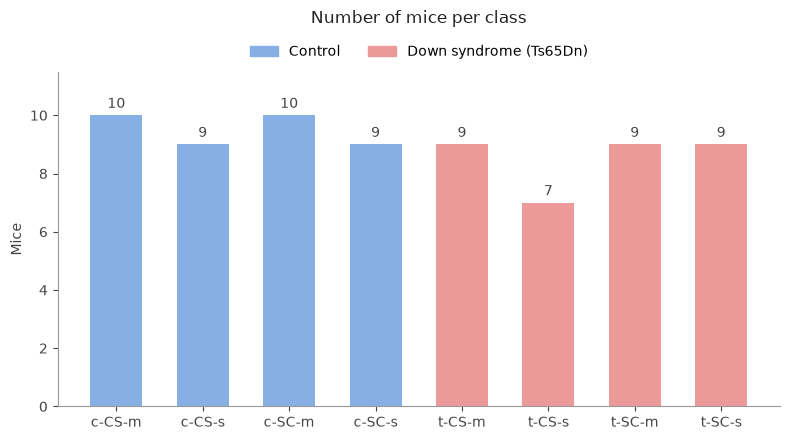

In [552]:
counts = mouse_info["class"].value_counts().reindex(class_order)
colors = [SOFT_BLUE if c.startswith("c") else SOFT_RED for c in counts.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(counts.index, counts.values, color=colors, width=0.6)
ax.bar_label(bars, padding=3, color="#444444")
ax.set_ylabel("Mice", color="#444444")
ax.set_ylim(0, counts.max() + 1.5)
ax.set_title("Number of mice per class", pad=35, color="#222222")
ax.legend(handles=[Patch(color=SOFT_BLUE, label="Control"),
                   Patch(color=SOFT_RED, label="Down syndrome (Ts65Dn)")],
          loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
clean_axes(ax)
plt.tight_layout()
plt.show()

- Classes are fairly **balanced**: 7–10 mice each.
- The smallest class is **t-CS-s** (failed learning, 7 mice).
- The dataset is small (72 mice), so results must be validated carefully.

## 3.2 Protein distributions and outliers
- **Skewness** measures how lopsided a distribution is: 0 is symmetric, and above 1 is strongly skewed.

Strongly skewed proteins (skew > 1): 17


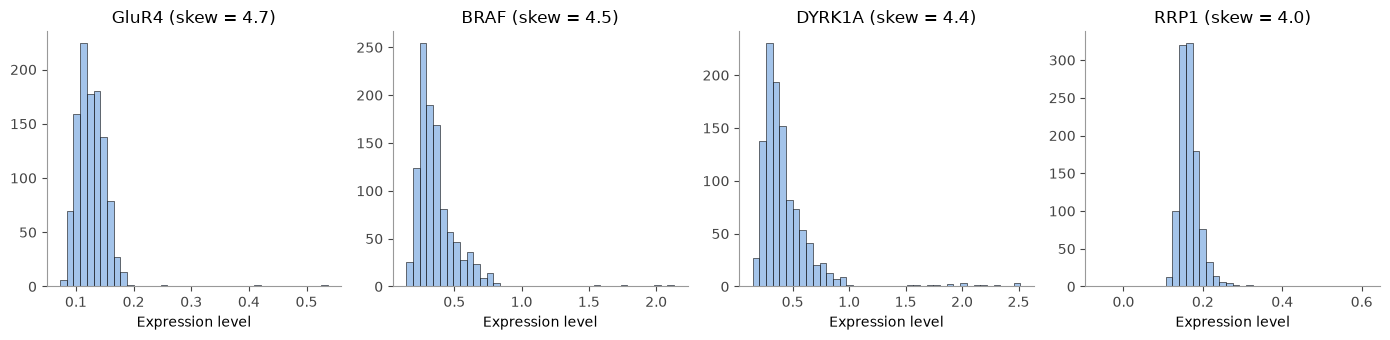

In [553]:
skewness = df[protein_cols].skew().sort_values(ascending=False)
print("Strongly skewed proteins (skew > 1):", (skewness > 1).sum())

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, p in zip(axes, skewness.index[:4]):
    sns.histplot(df[p], bins=40, ax=ax, color=SOFT_BLUE)
    ax.set(title=f"{p.removesuffix('_N')} (skew = {skewness[p]:.1f})",
           xlabel="Expression level", ylabel="")
    clean_axes(ax)
plt.tight_layout()
plt.show()

In [554]:
class_median = mouse_means.groupby(mouse_info["class"]).transform("median")
ratio_to_class = mouse_means / class_median

outliers = pd.DataFrame({
    "class": mouse_info["class"],
    "proteins_over_2x": (ratio_to_class > 2).sum(axis=1),
    "highest_ratio": ratio_to_class.max(axis=1).round(1),
    "top_protein": ratio_to_class.idxmax(axis=1).str.removesuffix("_N"),
}).sort_values(["proteins_over_2x", "highest_ratio"], ascending=False)

outliers.head(5)

,class,proteins_over_2x,highest_ratio,top_protein
Mouse,,,,
3484,c-CS-s,5,4.6,DYRK1A
293,t-SC-m,3,5.8,AcetylH3K9
3516,c-SC-s,2,9.2,AcetylH3K9
363,t-CS-m,2,2.4,pCAMKII
3418,t-SC-m,1,5.6,AcetylH3K9


### Which mice have extreme values?
- Each mouse is compared with the **median of its own class**, so normal class differences
  (e.g. high SOD1 in non-learning mice) are not counted as outliers.
- We count how many proteins are **more than 2×** the class median.

In [555]:
# The main outlier: which proteins are extreme (x times its class median)?
ratio_to_class.loc["3484"].sort_values(ascending=False).head(5).round(1)

DYRK1A_N    4.6
BRAF_N      4.6
pERK_N      4.3
ITSN1_N     3.4
pELK_N      2.8
Name: 3484, dtype: float64

### Finding: outlier mice
- **17 proteins** are strongly skewed, mostly because of a few very high values.
- **Two kinds of outliers:**
  - **3484** (c-CS-s): 5 MAPK-related proteins (DYRK1A, BRAF, pERK, ITSN1, pELK) about **4.5×** its class median.
    These cause most of the skewness and are the correlated group from Step 1.
  - **293** and **3516**: very high histone mark **AcetylH3K9** (5.8× and 9.2×).
- 293's high SOD1 is **normal** for a non-learning mouse, so it is not counted.
- **Decision:** keep all mice (they may be real biology, and classes are small).
  The models use `RobustScaler`, which is less affected by outliers.

## 3.3 Sanity check: chromosome 21 proteins
- Ts65Dn mice carry an **extra copy** of genes matching human chromosome 21.
- Proteins from these genes (**APP, ITSN1, DYRK1A, SOD1**) should be **higher** in Ts65Dn mice.

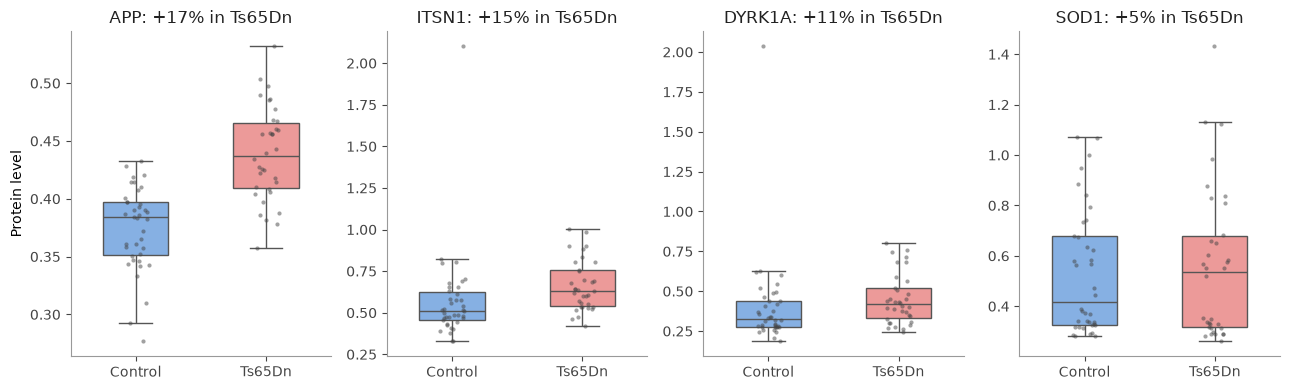

In [556]:
chr21 = ["APP_N", "ITSN1_N", "DYRK1A_N", "SOD1_N"]

fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for ax, p in zip(axes, chr21):
    d = mouse_means[[p]].join(mouse_info["Genotype"])

    sns.boxplot(data=d, x="Genotype", y=p, hue="Genotype", order=genotype_order,
                palette=genotype_colors, width=0.5, showfliers=False, legend=False,
                linecolor="#555555", saturation=1, ax=ax)
    sns.stripplot(data=d, x="Genotype", y=p, order=genotype_order,
                  color="#444444", size=3, alpha=0.5, ax=ax)

    m = d.groupby("Genotype")[p].mean()
    change = 100 * (m["Ts65Dn"] / m["Control"] - 1)
    ax.set_title(f"{p.removesuffix('_N')}: {change:+.0f}% in Ts65Dn", color="#222222")
    ax.set(xlabel="", ylabel="Protein level" if p == chr21[0] else "")

    clean_axes(ax)

plt.tight_layout()
plt.show()

- All four chromosome 21 proteins are **higher in Ts65Dn mice**:
  APP **+17%**, ITSN1 **+15%**, DYRK1A **+11%**, SOD1 **+5%**.
- The extreme point in ITSN1 and DYRK1A (Control group) is the outlier **mouse 3484**.

## 3.4 One protein separates learning from no-learning: SOD1
- SOD1 shows **two separate groups** of mice. We check whether behaviour explains this.

           min  mean   max
Behavior                  
C/S       0.26  0.32  0.39
S/C       0.44  0.75  1.43


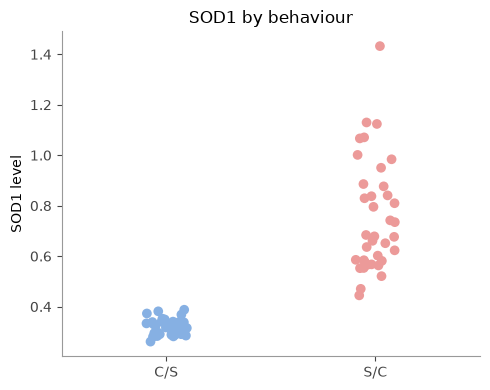

In [557]:
d = mouse_means[["SOD1_N"]].join(mouse_info["Behavior"])
print(d.groupby("Behavior")["SOD1_N"].agg(["min", "mean", "max"]).round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.stripplot(data=d, x="Behavior", y="SOD1_N", hue="Behavior",
              palette={"C/S": SOFT_BLUE, "S/C": SOFT_RED}, size=7, legend=False, ax=ax)
ax.set(title="SOD1 by behaviour", xlabel="", ylabel="SOD1 level")
clean_axes(ax)
plt.tight_layout()
plt.show()

- SOD1 is about **2.3× higher** in mice that did **not** learn (S/C) than in mice that learned (C/S).
- The groups **do not overlap**: every C/S mouse is below 0.39, and every S/C mouse is above 0.44.

## 3.5 Why replicates must stay together

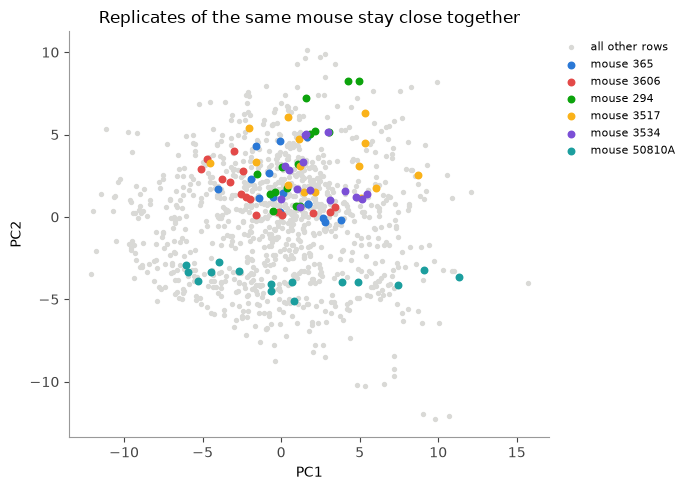

In [558]:
Xr = df[protein_cols].fillna(df[protein_cols].median())
pr = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(Xr))
r = pd.DataFrame(pr, columns=["PC1", "PC2"]).assign(Mouse=df["Mouse"].values)

pick = df["Mouse"].drop_duplicates().sample(6, random_state=1).tolist()
colors6 = ["#2a78d6", "#e34948", "#0ca30c", "#fab219", "#7b4fd6", "#1b9e9e"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(r["PC1"], r["PC2"], s=8, color="#d9d9d6", label="all other rows")
for m, c in zip(pick, colors6):
    s = r[r["Mouse"] == m]
    ax.scatter(s["PC1"], s["PC2"], s=22, color=c, label=f"mouse {m}")
ax.set(title="Replicates of the same mouse stay close together", xlabel="PC1", ylabel="PC2")
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1))
clean_axes(ax)
plt.tight_layout()
plt.show()

- Each colour is one mouse; its replicates stay **close together**.
- If one mouse's replicates were split between training and testing, the model could **recognise the mouse**
  instead of learning the class. This is why we split by mouse in Step 5.

### Summary of Step 3
- Classes are balanced: **7–10 mice** each.
- **Outlier mouse 3484** has very high DYRK1A, BRAF and pERK. It is kept but noted.
- **Chromosome 21 proteins are higher** in Down syndrome mice (APP +17%), as biology predicts.
- **SOD1 perfectly separates** learning (C/S) from no-learning (S/C) mice.
- PCA shows that **behaviour** causes the biggest differences; genotype and treatment effects are subtler.
- Replicates of a mouse are similar, so **all modelling must split by mouse**.

In [559]:
from scipy.stats import mannwhitneyu, kruskal, false_discovery_control
GREY, PURPLE = "#c8c8c4", "#b9a4e0"

# Step 4: Statistical tests
Which proteins differ between the key groups?

Three biological questions:
- **Learning (normal mice):** `c-SC-s` vs `c-CS-s`. What changes when a normal mouse learns?
- **Failed learning:** `c-CS-s` vs `t-CS-s`. How do Down syndrome mice differ when learning fails?
- **Rescue:** `t-CS-s` vs `t-CS-m`. What does memantine change in Down syndrome mice?

Methods:
- **One value per mouse** (average of its replicates), because replicates are not independent.
- **Mann–Whitney U test** (also called the Wilcoxon rank-sum test, as in the paper). It does not assume normal
  distributions and is robust to outliers such as mouse 3484.
- **FDR correction (Benjamini–Hochberg):** we test 76 proteins, so some will look significant by chance.
  The **q-value** is the p-value corrected for this. We call a protein significant if **q < 0.05**.
- **log2 fold change** (based on medians): how much higher or lower a protein is.
  +1 = twice as high, −1 = half as high, 0 = no change.

In [560]:
def compare_groups(group1, group2):
    """Mann-Whitney test for every protein, one value per mouse, with FDR correction."""
    mice1 = mouse_info.index[mouse_info["class"] == group1]
    mice2 = mouse_info.index[mouse_info["class"] == group2]
    rows = []
    for p in protein_cols:
        a = mouse_means.loc[mice1, p].dropna()
        b = mouse_means.loc[mice2, p].dropna()
        if len(a) < 3 or len(b) < 3:          # skip if too few mice measured
            continue
        p_value = mannwhitneyu(a, b, alternative="two-sided").pvalue
        rows.append({"protein": p.removesuffix("_N"), "n1": len(a), "n2": len(b),
                     "log2FC": np.log2(b.median() / a.median()), "p_value": p_value})
    res = pd.DataFrame(rows)
    res["q_value"] = false_discovery_control(res["p_value"], method="bh")
    return res.sort_values("p_value").reset_index(drop=True)

In [561]:
comparisons = {
    "Learning (normal mice)":         ("c-SC-s", "c-CS-s"),
    "Failed learning (DS vs normal)": ("c-CS-s", "t-CS-s"),
    "Rescue by memantine (DS)":       ("t-CS-s", "t-CS-m"),
}
results = {name: compare_groups(g1, g2) for name, (g1, g2) in comparisons.items()}

overview = pd.DataFrame({name: {"mice": f"{r.n1.iloc[0]} vs {r.n2.iloc[0]}",
                                "p < 0.05": (r["p_value"] < 0.05).sum(),
                                "q < 0.05 (FDR)": (r["q_value"] < 0.05).sum()}
                         for name, r in results.items()}).T
overview

,mice,p < 0.05,q < 0.05 (FDR)
Learning (normal mice),9 vs 9,27,17
Failed learning (DS vs normal),9 vs 7,13,0
Rescue by memantine (DS),7 vs 9,5,0


In [562]:
for name, r in results.items():
    print(f"\n{name}")
    display(r.head(6)[["protein", "log2FC", "p_value", "q_value"]].round(4))


Learning (normal mice)


,protein,log2FC,p_value,q_value
0,pERK,0.9056,0.0004,0.0075
1,SOD1,-1.4720,0.0004,0.0075
2,ARC,-0.2444,0.0004,0.0075
3,IL1B,-0.2826,0.0006,0.0075
4,pGSK3B,0.2013,0.0008,0.0075
5,DYRK1A,0.6563,0.0008,0.0075



Failed learning (DS vs normal)


,protein,log2FC,p_value,q_value
0,NR2A,-0.2067,0.0033,0.1582
1,P38,-0.2589,0.0052,0.1582
2,AMPKA,-0.2755,0.0115,0.1582
3,APP,0.1430,0.0115,0.1582
4,Tau,0.3872,0.0115,0.1582
5,pNR1,-0.1439,0.0164,0.1582



Rescue by memantine (DS)


,protein,log2FC,p_value,q_value
0,NUMB,-0.2257,0.0033,0.2524
1,SNCA,-0.1124,0.0115,0.4351
2,GluR3,0.1093,0.0229,0.4351
3,S6,-0.3992,0.0229,0.4351
4,Tau,-0.1915,0.0311,0.4730
5,ERK,-0.2700,0.0712,0.5304


## 4.1 Volcano plots
- Each dot is a protein.
- **x-axis:** size of the change (log2 fold change). **y-axis:** strength of evidence (−log10 p-value; higher = stronger).
- Dashed line: p = 0.05. **Red** = significant after FDR correction, **blue** = p < 0.05 only.

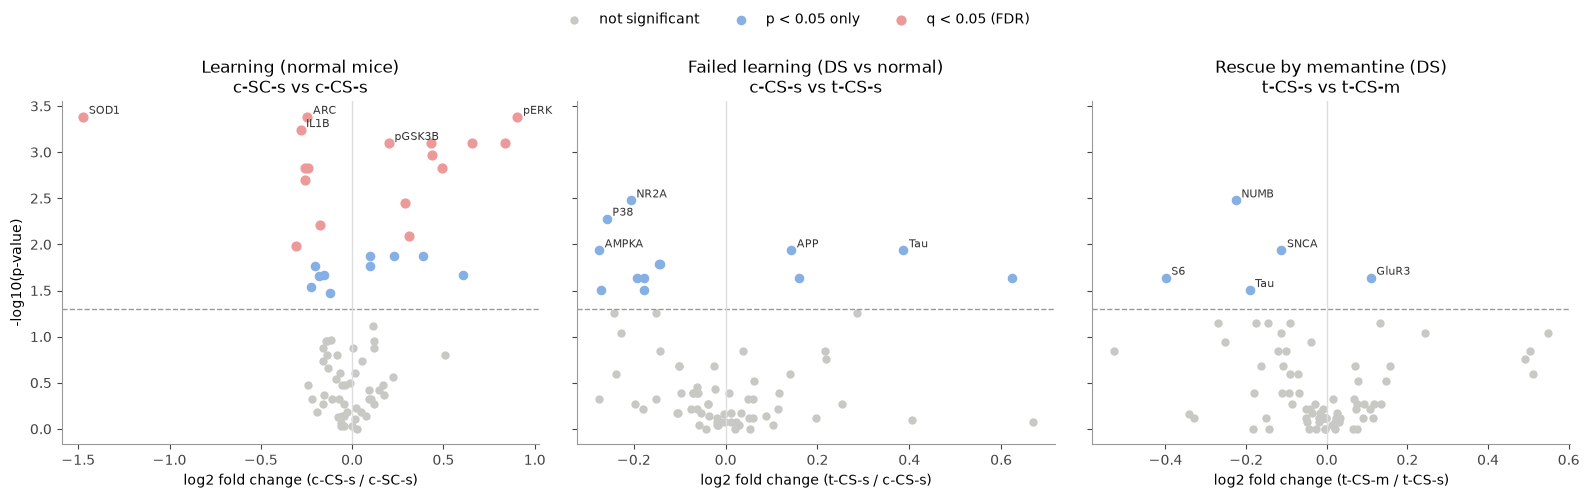

In [563]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    y = -np.log10(r["p_value"])
    sig = r["q_value"] < 0.05
    nominal = (r["p_value"] < 0.05) & ~sig
    rest = ~sig & ~nominal

    ax.scatter(r.loc[rest, "log2FC"], y[rest], s=25, color=GREY, label="not significant")
    ax.scatter(r.loc[nominal, "log2FC"], y[nominal], s=35, color=SOFT_BLUE, label="p < 0.05 only")
    ax.scatter(r.loc[sig, "log2FC"], y[sig], s=40, color=SOFT_RED, label="q < 0.05 (FDR)")
    ax.axhline(-np.log10(0.05), color="#999999", linestyle="--", linewidth=1)
    ax.axvline(0, color="#dddddd", linewidth=1)

    for _, row in r.head(5).iterrows():          # label the top 5 proteins
        ax.annotate(row["protein"], (row["log2FC"], -np.log10(row["p_value"])),
                    fontsize=8, xytext=(4, 2), textcoords="offset points", color="#333333")

    g1, g2 = comparisons[name]
    ax.set(title=f"{name}\n{g1} vs {g2}", xlabel=f"log2 fold change ({g2} / {g1})")
    clean_axes(ax)

axes[0].set_ylabel("-log10(p-value)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

- **Learning (normal mice): 17 proteins** are significant after FDR correction.
  The strongest are **SOD1** (much lower after learning), **pERK**, **ARC** and **IL1B**.
  ARC is a well-known "memory gene", which supports the result.
- **Failed learning: 13 proteins** have p < 0.05 (e.g. **NR2A, P38, Tau, APP**), but **none survive FDR correction**.
- **Rescue by memantine: only 5 proteins** have p < 0.05 (e.g. **NUMB, SNCA**), and **none survive FDR**.
- With only **7–9 mice per group**, small effects cannot be confirmed statistically. These proteins are
  **candidates**, not proven differences.

## 4.2 Why one value per mouse matters
- What happens if we (wrongly) treat all 1,077 rows as independent mice?

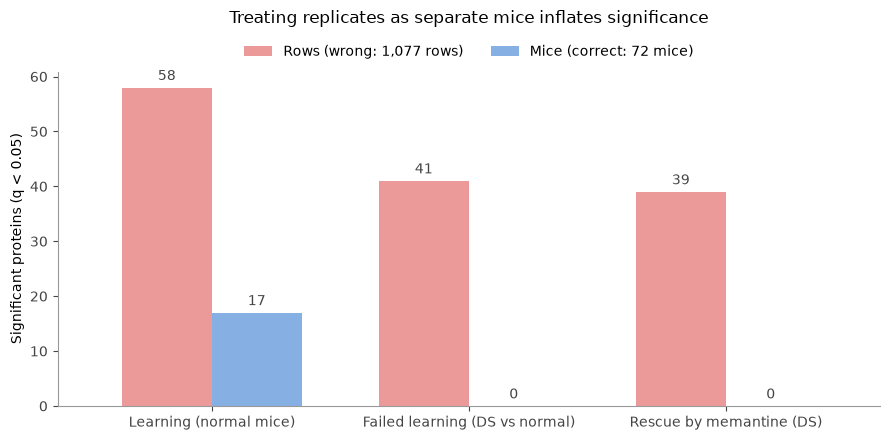

In [564]:
def count_significant_rows(group1, group2):
    """Wrong approach: every replicate row counted as a separate mouse."""
    p_values = [mannwhitneyu(df.loc[df["class"] == group1, p].dropna(),
                             df.loc[df["class"] == group2, p].dropna()).pvalue
                for p in protein_cols]
    return (false_discovery_control(p_values, method="bh") < 0.05).sum()

compare_n = pd.DataFrame({
    "Rows (wrong: 1,077 rows)": [count_significant_rows(g1, g2) for g1, g2 in comparisons.values()],
    "Mice (correct: 72 mice)":  [(r["q_value"] < 0.05).sum() for r in results.values()],
}, index=list(comparisons.keys()))

fig, ax = plt.subplots(figsize=(9, 4.5))
compare_n.plot.bar(ax=ax, color=[SOFT_RED, SOFT_BLUE], width=0.7, rot=0)
for container in ax.containers:
    ax.bar_label(container, padding=3, color="#444444")
ax.set(ylabel="Significant proteins (q < 0.05)", xlabel="")
ax.set_title("Treating replicates as separate mice inflates significance", pad=35)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
clean_axes(ax)
plt.tight_layout()
plt.show()

- Counting replicate rows as separate mice reports **41** significant proteins for failed learning.
  The correct mouse-level test finds **0**.
- The rows approach pretends there are 15× more mice than there really are, so the p-values become far too small.
  This mistake is called **pseudoreplication**.
- This is one of the main **improvements** of this project over a row-level analysis.

## 4.3 Normal, failed and rescued learning side by side
- The top candidates from the "failed learning" test, shown for the three learning groups.
- If memantine "rescues" a protein, the **Rescued** group should move back towards **Normal**.

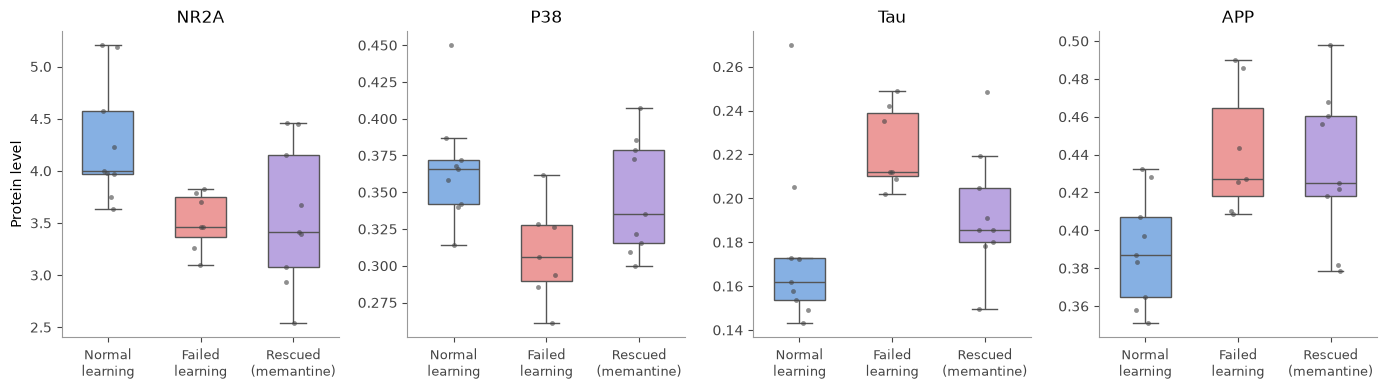

In [565]:
story = ["c-CS-s", "t-CS-s", "t-CS-m"]
story_labels = ["Normal\nlearning", "Failed\nlearning", "Rescued\n(memantine)"]
story_colors = {"c-CS-s": SOFT_BLUE, "t-CS-s": SOFT_RED, "t-CS-m": PURPLE}
top_proteins = ["NR2A_N", "P38_N", "Tau_N", "APP_N"]

sub = mouse_means[top_proteins].join(mouse_info["class"])
sub = sub[sub["class"].isin(story)]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, p in zip(axes, top_proteins):
    sns.boxplot(data=sub, x="class", y=p, hue="class", order=story, palette=story_colors,
                width=0.55, showfliers=False, legend=False, linecolor="#555555", saturation=1, ax=ax)
    sns.stripplot(data=sub, x="class", y=p, order=story, color="#444444", size=3.5, alpha=0.6, ax=ax)
    ax.set_xticks(range(3))
    ax.set_xticklabels(story_labels, fontsize=9)
    ax.set(title=p.removesuffix("_N"), xlabel="", ylabel="Protein level" if p == top_proteins[0] else "")
    clean_axes(ax)
plt.tight_layout()
plt.show()

- **P38** and **Tau** show a "rescue" pattern: failed learning moves them away from normal,
  and with memantine they move **back towards normal**.
- **NR2A** (part of the NMDA receptor, the target of memantine) is lower in failed learning
  and only partly restored.
- **APP** (chromosome 21) stays high with memantine. This is expected: memantine cannot remove
  the extra gene copy.
- These are **trends** in 7–9 mice, so they need confirmation (Steps 5–6).

## 4.4 Which proteins differ across all 8 classes?
- The **Kruskal–Wallis test** compares all 8 classes at once (a non-parametric version of ANOVA).

In [566]:
kw_rows = []
for p in protein_cols:
    groups = [mouse_means.loc[mouse_info["class"] == c, p].dropna() for c in class_order]
    kw_rows.append({"protein": p.removesuffix("_N"), "p_value": kruskal(*groups).pvalue})

kw = pd.DataFrame(kw_rows)
kw["q_value"] = false_discovery_control(kw["p_value"], method="bh")
kw = kw.sort_values("p_value").reset_index(drop=True)

print("Proteins that differ between the 8 classes (q < 0.05):", (kw["q_value"] < 0.05).sum())
kw.head(10)

Proteins that differ between the 8 classes (q < 0.05): 46


,protein,p_value,q_value
0,SOD1,1.189848e-09,9.042847e-08
1,pERK,3.495264e-09,1.328200e-07
2,DYRK1A,9.859091e-09,1.926208e-07
3,CaNA,1.013794e-08,1.926208e-07
4,ITSN1,3.336333e-08,5.071226e-07
5,P38,6.093297e-08,7.359420e-07
6,ARC,6.778413e-08,7.359420e-07
7,SNCA,1.020352e-07,9.693341e-07
8,Ubiquitin,2.545658e-07,2.149667e-06
9,BRAF,5.642165e-07,4.288046e-06


- **46 of 76 proteins** differ significantly across the 8 classes.
- The top proteins (**SOD1, pERK, DYRK1A, CaNA, ITSN1**) match the learning comparison,
  which confirms that **learning (behaviour)** drives the biggest differences, as PCA showed in Step 3.

In [567]:
for name, r in results.items():
    r.to_csv(f"stats_{name.split(' (')[0].replace(' ', '_').lower()}.csv", index=False)
kw.to_csv("stats_kruskal_all_classes.csv", index=False)
print("Saved statistics tables.")

Saved statistics tables.


### Summary of Step 4
- Tests were done on **one value per mouse** with **FDR correction** for 76 proteins.
- **Learning in normal mice changes 17 proteins** (strongest: SOD1, pERK, ARC, IL1B).
- **Failed learning and memantine rescue:** several candidates (NR2A, P38, Tau, NUMB),
  but **none survive FDR correction**. The groups are too small (7–9 mice) to confirm small effects.
- Treating replicates as separate mice would falsely report **41** significant proteins (**pseudoreplication**).
- **P38 and Tau** show a possible rescue pattern with memantine.
- Next: machine learning (Step 5), which uses **all proteins together**
  and may detect patterns that single-protein tests miss.

# Step 5: Machine learning
Goal: predict a mouse's class (8 groups) from its 76 proteins.

## 5.1 Features, target and groups
- `X` = proteins, `y` = class, `groups` = mouse ID (keeps each mouse's rows together).

In [568]:
X = df[protein_cols]
y = df["class"]
groups = df["Mouse"]

print("X:", X.shape, "| y:", y.shape, "| mice:", groups.nunique())

X: (1077, 76) | y: (1077,) | mice: 72


## 5.2 Split by mouse
- 5 folds; each mouse is wholly in training **or** testing, never both.

In [569]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

for i, (train, test) in enumerate(cv.split(X, y, groups), 1):
    shared = set(groups.iloc[train]) & set(groups.iloc[test])
    print(f"Fold {i}: train mice {groups.iloc[train].nunique()}, "
          f"test mice {groups.iloc[test].nunique()}, shared {len(shared)}")

Fold 1: train mice 58, test mice 14, shared 0
Fold 2: train mice 57, test mice 15, shared 0
Fold 3: train mice 58, test mice 14, shared 0
Fold 4: train mice 57, test mice 15, shared 0
Fold 5: train mice 58, test mice 14, shared 0


## 5.3 Baseline
- A model that always guesses the most common class. Real models must beat this.
- Pipeline: fill gaps (`KNNImputer`) → scale (`RobustScaler`) → model.

In [570]:
baseline = make_pipeline(KNNImputer(n_neighbors=5), RobustScaler(),
                         DummyClassifier(strategy="most_frequent"))
scores = cross_val_score(baseline, X, y, cv=cv, groups=groups, scoring="accuracy")
print(f"Baseline accuracy: {scores.mean():.0%}")

Baseline accuracy: 14%


## 5.4 Three models
- **Logistic Regression:** simple, linear.
- **Random Forest:** many decision trees.
- **SVM:** finds the best boundary between classes.

In [571]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "SVM": SVC(),
}

mouse_split = {"Baseline (guess most common)": scores.mean()}
for name, model in models.items():
    pipe = make_pipeline(KNNImputer(n_neighbors=5), RobustScaler(), model)
    s = cross_val_score(pipe, X, y, cv=cv, groups=groups, scoring="accuracy")
    mouse_split[name] = s.mean()
    print(f"{name}: {s.mean():.0%}  (folds: {s.round(2)})")

Logistic Regression: 66%  (folds: [0.79 0.5  0.64 0.71 0.68])
Random Forest: 59%  (folds: [0.63 0.5  0.68 0.51 0.63])
SVM: 69%  (folds: [0.71 0.54 0.79 0.7  0.7 ])


In [572]:
ml_results = pd.Series(mouse_split, name="Accuracy (split by mouse)").round(2).to_frame()
ml_results

,Accuracy (split by mouse)
Baseline (guess most common),0.14
Logistic Regression,0.66
Random Forest,0.59
SVM,0.69


### Check: does scaling make proteins comparable?
- `RobustScaler` (used in Step 5) centres each protein on its **median = 0** and sets its **spread (IQR) = 1**.
- This check does **not** change `df`; the real scaling happens inside the model pipeline.

     median  IQR
min    -0.0  1.0
max     0.0  1.0


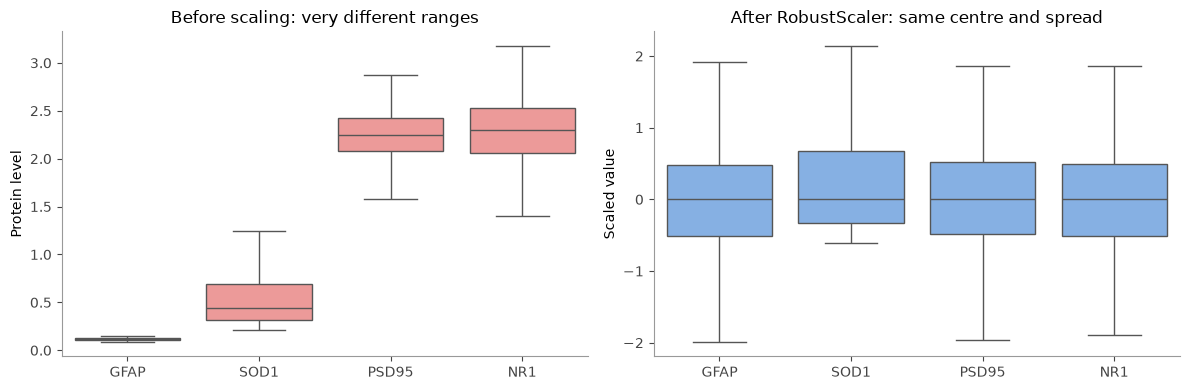

In [573]:
scaled = pd.DataFrame(RobustScaler().fit_transform(df[protein_cols]), columns=protein_cols)

# Numbers: after scaling every protein has median 0 and IQR 1
check = pd.DataFrame({"median": scaled.median(),
                      "IQR": scaled.quantile(0.75) - scaled.quantile(0.25)})
print(check.agg(["min", "max"]).round(3))

# Picture: 4 proteins before and after
example = ["GFAP_N", "SOD1_N", "PSD95_N", "NR1_N"]
names = [p.removesuffix("_N") for p in example]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df[example].set_axis(names, axis=1), color=SOFT_RED, saturation=1,
            showfliers=False, linecolor="#555555", ax=axes[0])
axes[0].set(title="Before scaling: very different ranges", ylabel="Protein level")
sns.boxplot(data=scaled[example].set_axis(names, axis=1), color=SOFT_BLUE, saturation=1,
            showfliers=False, linecolor="#555555", ax=axes[1])
axes[1].set(title="After RobustScaler: same centre and spread", ylabel="Scaled value")
for ax in axes:
    clean_axes(ax)
plt.tight_layout()
plt.show()

## 5.5 One prediction per mouse
- Each mouse has ~15 rows, so its rows **vote**: the most common prediction becomes the mouse's prediction.

In [574]:
best_model = make_pipeline(KNNImputer(n_neighbors=5), RobustScaler(), SVC())
row_pred = cross_val_predict(best_model, X, y, cv=cv, groups=groups)

votes = (pd.DataFrame({"Mouse": groups, "true": y, "pred": row_pred})
           .groupby("Mouse")
           .agg(true=("true", "first"), pred=("pred", lambda s: s.mode()[0])))

correct = (votes["true"] == votes["pred"])
print(f"Row accuracy:   {accuracy_score(y, row_pred):.0%}")
print(f"Mouse accuracy: {correct.mean():.0%}  ({correct.sum()} of {len(votes)} mice)")

Row accuracy:   69%
Mouse accuracy: 76%  (55 of 72 mice)


## 5.6 Which classes get mixed up?
- Rows = true class, columns = predicted class. The diagonal = correct.

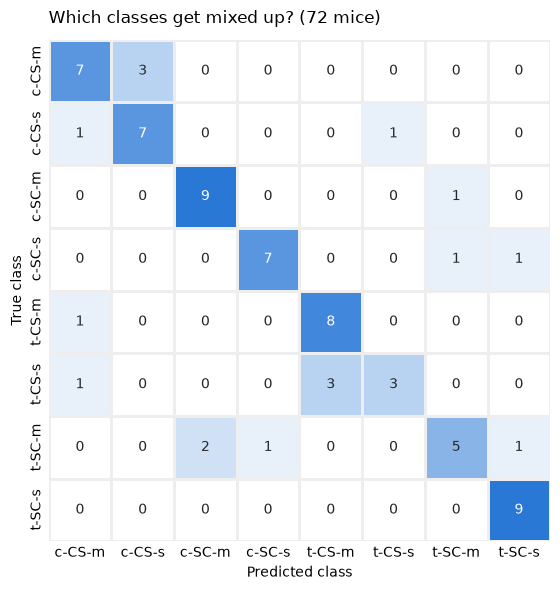

In [575]:
cm = pd.DataFrame(confusion_matrix(votes["true"], votes["pred"], labels=class_order),
                  index=class_order, columns=class_order)
blues = LinearSegmentedColormap.from_list("soft_blues", ["#ffffff", "#2a78d6"])

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap=blues, cbar=False,
            linewidths=1, linecolor="#eeeeee", square=True, ax=ax)
ax.set(xlabel="Predicted class", ylabel="True class")
ax.set_title("Which classes get mixed up? (72 mice)", loc="left", pad=12)
ax.tick_params(length=0)
plt.tight_layout()
plt.show()

- **Failed learning (t-CS-s)** is hardest: 3 of 7 mice are predicted as **rescued (t-CS-m)**.
- **c-CS-s vs c-CS-m** are also mixed up: memantine changes little in normal mice.

## 5.7 Simpler yes/no questions
- The same model, predicting one factor at a time (guessing = 50%).

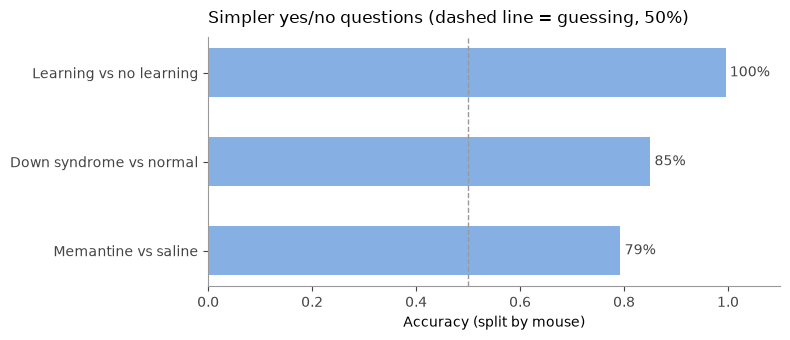

In [576]:
tasks = {"Behavior": "Learning vs no learning",
         "Genotype": "Down syndrome vs normal",
         "Treatment": "Memantine vs saline"}

binary = pd.Series({label: cross_val_score(best_model, X, df[col], cv=cv, groups=groups).mean()
                    for col, label in tasks.items()}).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(binary.index, binary.values, color=SOFT_BLUE, height=0.55)
ax.bar_label(bars, labels=[f"{v*100:.0f}%" for v in binary.values], padding=3, color="#444444")
ax.axvline(0.5, color="#999999", linestyle="--", linewidth=1)
ax.set(xlim=(0, 1.1), xlabel="Accuracy (split by mouse)")
ax.set_title("Simpler yes/no questions (dashed line = guessing, 50%)", loc="left", pad=10)
clean_axes(ax)
plt.tight_layout()
plt.show()

- **Learning: ~100%** · **Down syndrome: 85%** · **Memantine: 79%**
- Learning leaves a strong signal; genotype and drug effects are weaker and spread over many proteins.

### Summary of Step 5
- Best model (SVM): **69% per row, 76% per mouse** for 8 classes (guessing: 14%).
- Failed and rescued learning are the hardest classes to tell apart.

In [577]:
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr

# Step 6: Which proteins does the model rely on?
- **Permutation importance:** shuffle one protein in the **test mice** and measure how much accuracy drops.
  A big drop = the model needs that protein.
- Done in each of the 5 folds (split by mouse), so it is measured on **unseen mice**.

In [578]:
fold_importances = []
for train, test in cv.split(X, y, groups):
    best_model.fit(X.iloc[train], y.iloc[train])
    result = permutation_importance(best_model, X.iloc[test], y.iloc[test],
                                    n_repeats=10, random_state=42, n_jobs=-1)
    fold_importances.append(result.importances_mean)

importance = pd.DataFrame(fold_importances, columns=[p.removesuffix("_N") for p in protein_cols])
imp_summary = (pd.DataFrame({"importance": importance.mean(), "std": importance.std()})
                 .sort_values("importance", ascending=False))
imp_summary.head(10).round(3)

,importance,std
APP,0.055,0.030
ITSN1,0.029,0.021
ADARB1,0.024,0.012
DYRK1A,0.022,0.021
nNOS,0.021,0.017
BRAF,0.021,0.026
pP70S6,0.020,0.017
Tau,0.020,0.012
pPKCAB,0.018,0.012
NUMB,0.018,0.007


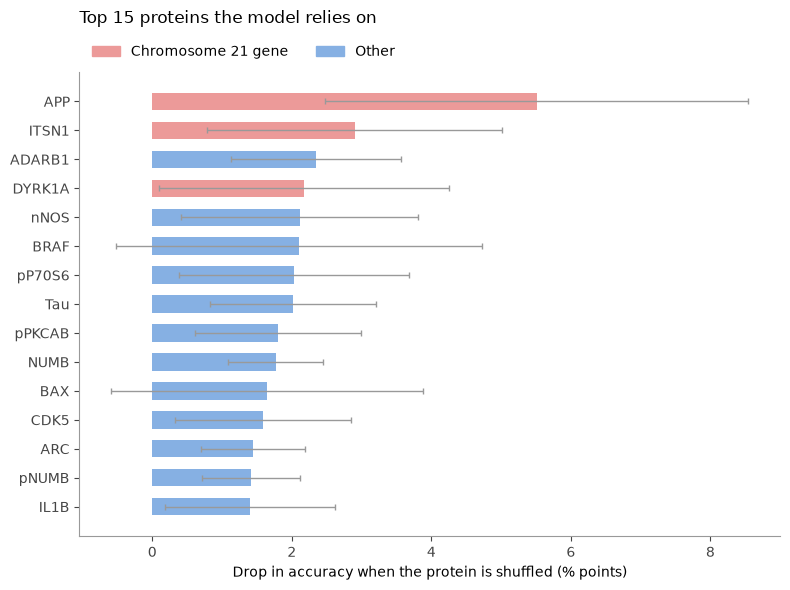

In [579]:
top = imp_summary.head(15).iloc[::-1] * 100          # in percentage points
chr21 = {"APP", "ITSN1", "DYRK1A", "SOD1"}
colors = [SOFT_RED if p in chr21 else SOFT_BLUE for p in top.index]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["importance"], xerr=top["std"], color=colors, height=0.6,
        error_kw={"ecolor": "#999999", "capsize": 2, "elinewidth": 1})
ax.set(xlabel="Drop in accuracy when the protein is shuffled (% points)", ylabel="")
ax.set_title("Top 15 proteins the model relies on", loc="left", pad=35)
ax.legend(handles=[Patch(color=SOFT_RED, label="Chromosome 21 gene"),
                   Patch(color=SOFT_BLUE, label="Other")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
clean_axes(ax)
plt.tight_layout()
plt.show()

- **APP** is the most important (accuracy drops ~5.5 points without it), followed by **ITSN1** and **DYRK1A**:
  all **chromosome 21 genes**, which help the model tell Down syndrome from normal mice.
- **Tau** and **NUMB** are also in the top 10. Both were candidates for the memantine rescue in Step 4.
- Error bars are wide: importance varies between folds, as expected with only 72 mice.

In [580]:
compare = imp_summary[["importance"]].copy()
compare["model_rank"] = range(1, len(compare) + 1)
compare["stats_rank"] = kw.set_index("protein")["p_value"].rank().astype(int)

print("Rank correlation:", round(spearmanr(compare["model_rank"], compare["stats_rank"])[0], 2))
compare.loc[["APP", "ITSN1", "DYRK1A", "SOD1", "pERK"], ["model_rank", "stats_rank"]]

Rank correlation: 0.38


,model_rank,stats_rank
APP,1,13
ITSN1,2,5
DYRK1A,4,3
SOD1,64,1
pERK,24,2


- The two rankings agree only moderately (r = 0.38): **ITSN1** and **DYRK1A** rank high in both.
- **SOD1** is #1 in the statistics but only #64 for the model. It separates learning perfectly, but so do
  many other proteins, so shuffling SOD1 alone hardly hurts: the model uses the others instead.
- Lesson: permutation importance **underestimates proteins that have "backups"** (correlated proteins).
  Statistics measure each protein **alone**; the model measures what each protein **adds**.

### Summary of Step 6
- The model relies most on **chromosome 21 proteins** (APP, ITSN1, DYRK1A) and on **Tau** and **NUMB**.
- Learning-related proteins like SOD1 rank low because their information is shared with other proteins.

# Step 7: Conclusions
- The 15 replicates per mouse are **not independent**: ignoring this inflates accuracy (69% → ~100%)
  and significant proteins (0 → 41).
- **Learning** causes the strongest changes (17 proteins; SOD1, pERK, ARC).
- **Chromosome 21 proteins** (APP, ITSN1, DYRK1A) are higher in Down syndrome mice and are the model's key features.
- Failed and rescued learning are hard to separate; **P38, Tau and NUMB** are rescue candidates needing confirmation.
- **ARC_N and pS6_N are duplicated** in the original data.
- **Limitations:** only 7–10 mice per class; correlated proteins make single-protein importance hard to interpret.